# Predicting Student Academic Performance Using Multi-Source Data — Corrected Analysis

This notebook replaces the earlier `stud_predict.ipynb`. It fixes the problems found during review:

| # | Problem in the earlier notebook | Fix applied here |
|---|---|---|
| 1 | "Dataset C" was loaded from `student_performance.csv`, which on Windows is the same file as `Student_Performance.csv` (Dataset A). The external test therefore re-used the training data. | Dataset C is now the Nabeel synthetic dataset, saved under a distinct name (`dataset_C_nabeel.csv`). |
| 2 | Dataset A contains 10,000 exact duplicate rows (25,000 rows, 15,000 unique students). Copies of the same student fell into both train and test sets. | Duplicates are removed before any split. |
| 3 | Study hours were per **day** in Dataset A (0.5–8) but per **week** in Datasets B and C. | Dataset A study hours are converted to weekly hours (× 7). |
| 4 | Dataset B's `Parental_Involvement` (Low/Medium/High) was renamed to `parent_education`; B's real `Parental_Education_Level` was discarded. | B's `Parental_Education_Level` is used and both datasets are mapped to a common three-level scale. |
| 5 | A `source` column (A/B/C) was fed to the models as a predictor. | Removed. Source is kept only for reporting. |
| 6 | No baseline, one train/test split, no uncertainty. | Mean and linear-regression baselines; 5-fold cross-validation (mean ± SD); hold-out set kept for diagnostic plots. |
| 7 | No test of whether combining sources helps. | Single-source vs multi-source comparison. |
| 8 | Error-band percentages and feature importances were read off plots. | All are computed in code (permutation importance on the hold-out set). |

All random processes use `RANDOM_STATE = 42`. File names expected in the `data/` folder:
`Student_Performance.csv` (A), `StudentPerformanceFactors.csv` (B), `dataset_C_nabeel.csv` (C), `student-mat.csv` and `student-por.csv` (D, UCI).

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

import sklearn
import xgboost
from sklearn.model_selection import train_test_split, KFold, cross_validate, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
DATA_DIR = "data/"      # folder holding the five CSV files (see data/README.md)
FIG_DIR = "figures/"
import os; os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})
PALETTE = {"A": "#2a6f97", "B": "#e07a5f", "C": "#3d8b5f"}

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 2.1.4


## 2. Load and audit the three datasets

In [2]:
df_A_raw = pd.read_csv(DATA_DIR + "Student_Performance.csv")         # Dataset A (Bedmutha)
df_B_raw = pd.read_csv(DATA_DIR + "StudentPerformanceFactors.csv")   # Dataset B (Student Performance Factors)
df_C_raw = pd.read_csv(DATA_DIR + "dataset_C_nabeel.csv")            # Dataset C (Nabeel, synthetic) - external only

for name, d in [("A", df_A_raw), ("B", df_B_raw), ("C", df_C_raw)]:
    print(f"Dataset {name}: {d.shape[0]:,} rows x {d.shape[1]} columns | "
          f"exact duplicate rows: {d.duplicated().sum():,} | missing cells: {d.isna().sum().sum():,}")

# Guard against the earlier mistake: C must not have A's schema
assert set(df_C_raw.columns) != set(df_A_raw.columns), "Dataset C has the same columns as A - wrong file!"
print("\nDataset C columns:", df_C_raw.columns.tolist())

Dataset A: 25,000 rows x 16 columns | exact duplicate rows: 10,000 | missing cells: 0
Dataset B: 6,607 rows x 20 columns | exact duplicate rows: 0 | missing cells: 235
Dataset C: 1,000,000 rows x 6 columns | exact duplicate rows: 0 | missing cells: 0

Dataset C columns: ['student_id', 'weekly_self_study_hours', 'attendance_percentage', 'class_participation', 'total_score', 'grade']


In [3]:
print("Dataset A: unique student_id =", df_A_raw.student_id.nunique())
print("Copies per student_id:", df_A_raw.groupby("student_id").size().value_counts().sort_index().to_dict())
print("\nStudy-hours ranges (evidence of different units):")
print(f"  A study_hours            : {df_A_raw.study_hours.min()} - {df_A_raw.study_hours.max()}  (per day)")
print(f"  B Hours_Studied          : {df_B_raw.Hours_Studied.min()} - {df_B_raw.Hours_Studied.max()}  (per week)")
print(f"  C weekly_self_study_hours: {df_C_raw.weekly_self_study_hours.min()} - {df_C_raw.weekly_self_study_hours.max()}  (per week)")
print("\nMissing values in B:")
print(df_B_raw.isna().sum()[lambda s: s > 0])

Dataset A: unique student_id = 15000
Copies per student_id: {1: 7735, 2: 5089, 3: 1701, 4: 404, 5: 59, 6: 11, 7: 1}

Study-hours ranges (evidence of different units):
  A study_hours            : 0.5 - 8.0  (per day)
  B Hours_Studied          : 1 - 44  (per week)
  C weekly_self_study_hours: 0.0 - 40.0  (per week)

Missing values in B:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64


## 3. Harmonisation

* **Duplicates** – exact duplicate rows in A are dropped (keeps 15,000 unique students).
* **Study hours** – A's daily hours × 7 → weekly hours, matching B and C.
* **Parent education** – mapped to a common three-level scale:

| Common level | Dataset A | Dataset B |
|---|---|---|
| `secondary_or_less` | no formal, high school | High School |
| `tertiary` | diploma, graduate | College |
| `postgraduate` | post graduate, phd | Postgraduate |

* **Categorical text** – lower-cased (`Yes`/`yes`, `Public`/`public`).
* **Target** – `overall_score` (A) and `Exam_Score` (B) → `score`, clipped to 0–100 (B contains one value of 101).
* B's `Parental_Involvement` is **not** used as parent education (different construct).

In [4]:
EDU_MAP = {
    # Dataset A
    "no formal": "secondary_or_less", "high school": "secondary_or_less",
    "diploma": "tertiary", "graduate": "tertiary",
    "post graduate": "postgraduate", "phd": "postgraduate",
    # Dataset B
    "college": "tertiary", "postgraduate": "postgraduate",
}

def lower_strings(d):
    d = d.copy()
    for c in d.columns:
        if d[c].dtype == object or str(d[c].dtype).startswith("str"):
            d[c] = d[c].str.strip().str.lower()
    return d

# ---- Dataset A ----
A = lower_strings(df_A_raw.drop_duplicates())
A = pd.DataFrame({
    "study_hours_week": A["study_hours"] * 7,
    "attendance": A["attendance_percentage"],
    "parent_education": A["parent_education"].map(EDU_MAP),
    "school_type": A["school_type"],
    "internet_access": A["internet_access"],
    "gender": A["gender"],
    "score": A["overall_score"].clip(0, 100),
})
A["source"] = "A"

# ---- Dataset B ----
B = lower_strings(df_B_raw)
B = pd.DataFrame({
    "study_hours_week": B["Hours_Studied"],
    "attendance": B["Attendance"],
    "parent_education": B["Parental_Education_Level"].map(EDU_MAP),   # NaN stays NaN -> imputed later
    "school_type": B["School_Type"],
    "internet_access": B["Internet_Access"],
    "gender": B["Gender"],
    "score": B["Exam_Score"].clip(0, 100),
})
B["source"] = "B"

dev = pd.concat([A, B], ignore_index=True)

# ---- Dataset C (external; only study hours and attendance overlap) ----
C = pd.DataFrame({
    "study_hours_week": df_C_raw["weekly_self_study_hours"],
    "attendance": df_C_raw["attendance_percentage"],
    "score": df_C_raw["total_score"].clip(0, 100),
})
C["source"] = "C"

print(f"A after de-duplication: {len(A):,} | B: {len(B):,} | pooled development set: {len(dev):,} | C: {len(C):,}")
print("\nUnmapped parent-education values:", dev.parent_education.isna().sum(), "(B's original missing values)")
print("\nCategory levels after harmonisation:")
for c in ["parent_education", "school_type", "internet_access", "gender"]:
    print(f"  {c}: " + ", ".join(f"{k} (A={(A[c]==k).sum()}, B={(B[c]==k).sum()})" for k in sorted(dev[c].dropna().unique())))

A after de-duplication: 15,000 | B: 6,607 | pooled development set: 21,607 | C: 1,000,000

Unmapped parent-education values: 90 (B's original missing values)

Category levels after harmonisation:
  parent_education: postgraduate (A=4961, B=1305), secondary_or_less (A=4977, B=3223), tertiary (A=5062, B=1989)
  school_type: private (A=7587, B=2009), public (A=7413, B=4598)
  internet_access: no (A=2246, B=499), yes (A=12754, B=6108)
  gender: female (A=4979, B=2793), male (A=4979, B=3814), other (A=5042, B=0)


In [5]:
summary = (pd.concat([dev, C]).groupby("source")[["study_hours_week", "attendance", "score"]]
           .agg(["mean", "std", "min", "max"]).round(2))
summary

study_hours_week                    ...  score                    
                   mean    std  min   max  ...   mean    std   min    max
source                                     ...                           
A                 29.82  15.21  3.5  56.0  ...  64.02  18.98  14.5  100.0
B                 19.98   5.99  1.0  44.0  ...  67.24   3.89  55.0  100.0
C                 15.03   6.90  0.0  40.0  ...  84.28  15.43   9.4  100.0

[3 rows x 12 columns]

## 4. Exploratory analysis

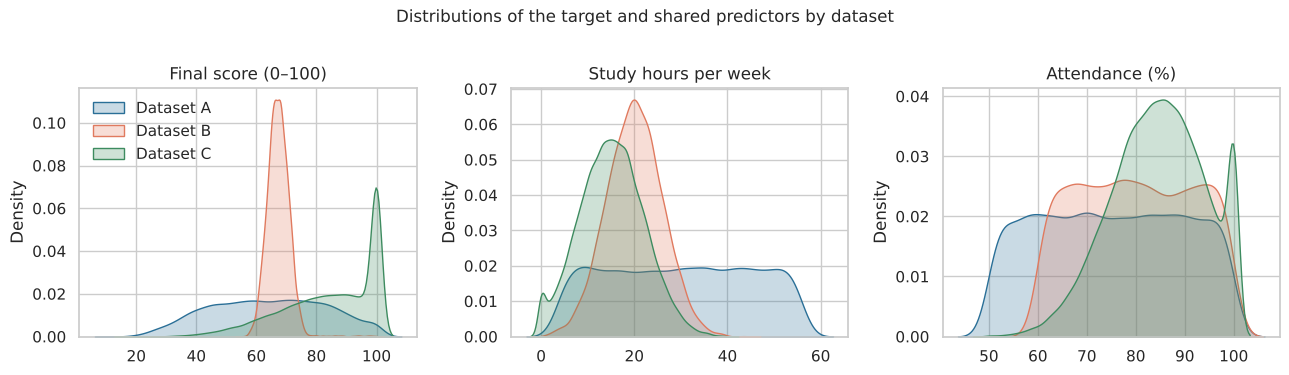

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, title in zip(axes, ["score", "study_hours_week", "attendance"],
                          ["Final score (0–100)", "Study hours per week", "Attendance (%)"]):
    for s, d in [("A", A), ("B", B), ("C", C.sample(50_000, random_state=RANDOM_STATE))]:
        sns.kdeplot(d[col], ax=ax, label=f"Dataset {s}", color=PALETTE[s], fill=True, alpha=0.25, common_norm=False, warn_singular=False)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Density")
axes[0].legend(frameon=False)
fig.suptitle("Distributions of the target and shared predictors by dataset", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_1_distributions.png", bbox_inches="tight"); plt.show()

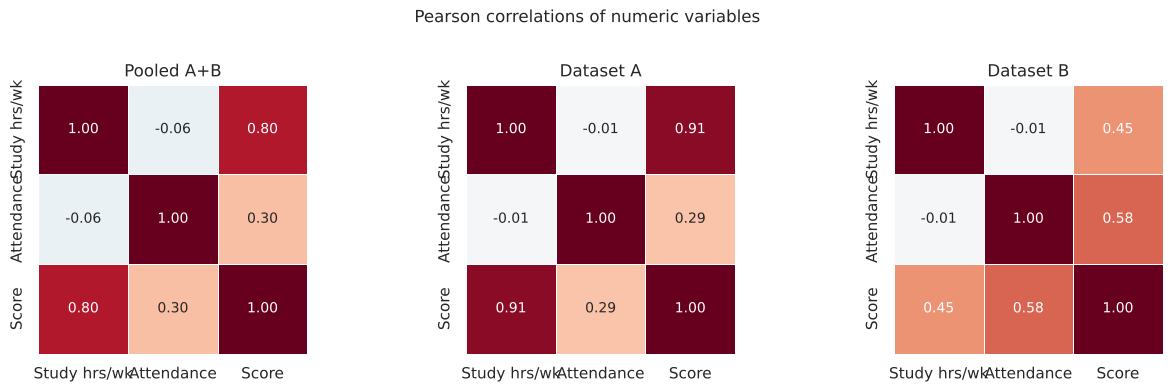

,Pooled,A,B,C
study_hours_week,0.801,0.906,0.446,0.812
attendance,0.299,0.288,0.581,-0.001


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
labels = ["Study hrs/wk", "Attendance", "Score"]
for ax, (s, d) in zip(axes, [("Pooled A+B", dev), ("Dataset A", A), ("Dataset B", B)]):
    corr = d[["study_hours_week", "attendance", "score"]].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax, square=True, linewidths=0.5)
    ax.set_title(s)
fig.suptitle("Pearson correlations of numeric variables", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_2_correlations.png", bbox_inches="tight"); plt.show()

corr_tbl = pd.DataFrame({s: d[["study_hours_week", "attendance"]].corrwith(d["score"])
                         for s, d in [("Pooled", dev), ("A", A), ("B", B), ("C", C)]}).round(3)
corr_tbl

## 5. Modelling set-up

* Features (no `source`): weekly study hours, attendance, parent education, school type, internet access, gender.
* Hold-out split: 80/20, stratified by source so A and B keep their proportions.
* Cross-validation: 5-fold `KFold(shuffle=True)` on the 80 % training portion.
* Model settings follow Chapter 3 (RF: 200 trees; XGBoost: 200 trees, learning rate 0.1, depth 6; Stacking: RF + XGBoost → Ridge meta-learner, 5-fold internal CV).

In [8]:
NUM = ["study_hours_week", "attendance"]
CAT = ["parent_education", "school_type", "internet_access", "gender"]
FEATURES = NUM + CAT

def make_preprocessor(num=NUM, cat=CAT):
    steps = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num)]
    if cat:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(steps)

def rf():  return RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
def xgb(): return XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6,
                               random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
def stack():
    return StackingRegressor(estimators=[("rf", rf()), ("xgb", xgb())],
                             final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=1)

def build_models(num=NUM, cat=CAT):
    return {
        "Mean baseline":     Pipeline([("prep", make_preprocessor(num, cat)), ("model", DummyRegressor())]),
        "Linear regression": Pipeline([("prep", make_preprocessor(num, cat)), ("model", LinearRegression())]),
        "Random Forest":     Pipeline([("prep", make_preprocessor(num, cat)), ("model", rf())]),
        "XGBoost":           Pipeline([("prep", make_preprocessor(num, cat)), ("model", xgb())]),
        "Stacking":          Pipeline([("prep", make_preprocessor(num, cat)), ("model", stack())]),
    }

def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

train_df, test_df = train_test_split(dev, test_size=0.2, random_state=RANDOM_STATE, stratify=dev["source"])
X_train, y_train = train_df[FEATURES], train_df["score"]
X_test,  y_test  = test_df[FEATURES],  test_df["score"]
print(f"Train: {len(train_df):,} (A={sum(train_df.source=='A'):,}, B={sum(train_df.source=='B'):,}) | "
      f"Test: {len(test_df):,} (A={sum(test_df.source=='A'):,}, B={sum(test_df.source=='B'):,})")

Train: 17,285 (A=12,000, B=5,285) | Test: 4,322 (A=3,000, B=1,322)


## 6. Five-fold cross-validation on the training portion

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_rows = []
for name, model in build_models().items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {"Model": name}
    for m in scoring:
        vals = res[f"test_{m}"] * (-1 if m != "R2" else 1)
        row[f"{m} mean"], row[f"{m} sd"] = vals.mean(), vals.std(ddof=1)
    cv_rows.append(row)
    print(f"{name:18s} MAE {row['MAE mean']:.2f} ± {row['MAE sd']:.2f} | RMSE {row['RMSE mean']:.2f} ± {row['RMSE sd']:.2f} | R² {row['R2 mean']:.4f} ± {row['R2 sd']:.4f}")
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(4)

Mean baseline      MAE 12.12 ± 0.20 | RMSE 15.99 ± 0.21 | R² -0.0002 ± 0.0003
Linear regression  MAE 6.09 ± 0.09 | RMSE 7.46 ± 0.10 | R² 0.7821 ± 0.0069
Random Forest      MAE 4.47 ± 0.14 | RMSE 5.86 ± 0.18 | R² 0.8654 ± 0.0083
XGBoost            MAE 4.24 ± 0.13 | RMSE 5.47 ± 0.14 | R² 0.8828 ± 0.0065
Stacking           MAE 4.24 ± 0.13 | RMSE 5.47 ± 0.14 | R² 0.8828 ± 0.0065


,MAE mean,MAE sd,RMSE mean,RMSE sd,R2 mean,R2 sd
Model,,,,,,
Mean baseline,12.1175,0.2004,15.9918,0.2126,-0.0002,0.0003
Linear regression,6.0932,0.0867,7.4620,0.0985,0.7821,0.0069
Random Forest,4.4739,0.1417,5.8646,0.1771,0.8654,0.0083
XGBoost,4.2394,0.1294,5.4714,0.1404,0.8828,0.0065
Stacking,4.2399,0.1302,5.4721,0.1408,0.8828,0.0065


## 7. Hold-out test set (20 %)

In [10]:
fitted, preds, holdout_rows = {}, {}, []
for name, model in build_models().items():
    model.fit(X_train, y_train)
    fitted[name], preds[name] = model, model.predict(X_test)
    row = {"Model": name, **metrics(y_test, preds[name])}
    for s in ["A", "B"]:
        mask = (test_df.source == s).values
        row[f"R2 within {s}"] = r2_score(y_test[mask], preds[name][mask])
        row[f"MAE within {s}"] = mean_absolute_error(y_test[mask], preds[name][mask])
    holdout_rows.append(row)
holdout_table = pd.DataFrame(holdout_rows).set_index("Model")
holdout_table.round(4)

,MAE,RMSE,R2,R2 within A,MAE within A,R2 within B,MAE within B
Model,,,,,,,
Mean baseline,12.2001,16.1607,-0.0000,-0.0035,16.1072,-0.3130,3.3338
Linear regression,6.0924,7.4523,0.7873,0.8638,5.8048,-3.2854,6.7448
Random Forest,4.5040,5.8422,0.8693,0.8885,5.3847,-0.1934,2.5053
XGBoost,4.2629,5.4873,0.8847,0.8980,5.1809,0.1368,2.1798
Stacking,4.2629,5.4861,0.8848,0.8981,5.1798,0.1335,2.1821


In [11]:
def error_bands(y, p, bands=(3, 6, 10)):
    e = np.abs(np.asarray(y) - np.asarray(p))
    return {f"within ±{b}": 100 * np.mean(e <= b) for b in bands}

band_table = pd.DataFrame({n: error_bands(y_test, preds[n]) for n in ["Linear regression", "Random Forest", "XGBoost", "Stacking"]}).T.round(2)
band_table["mean residual"] = [np.mean(y_test - preds[n]) for n in band_table.index]
band_table.round(2)

,within ±3,within ±6,within ±10,mean residual
Linear regression,28.20,54.42,82.14,0.10
Random Forest,44.35,69.34,91.65,0.03
XGBoost,46.11,70.87,94.45,0.02
Stacking,46.16,70.68,94.47,0.03


## 8. Diagnostic plots for the three main models

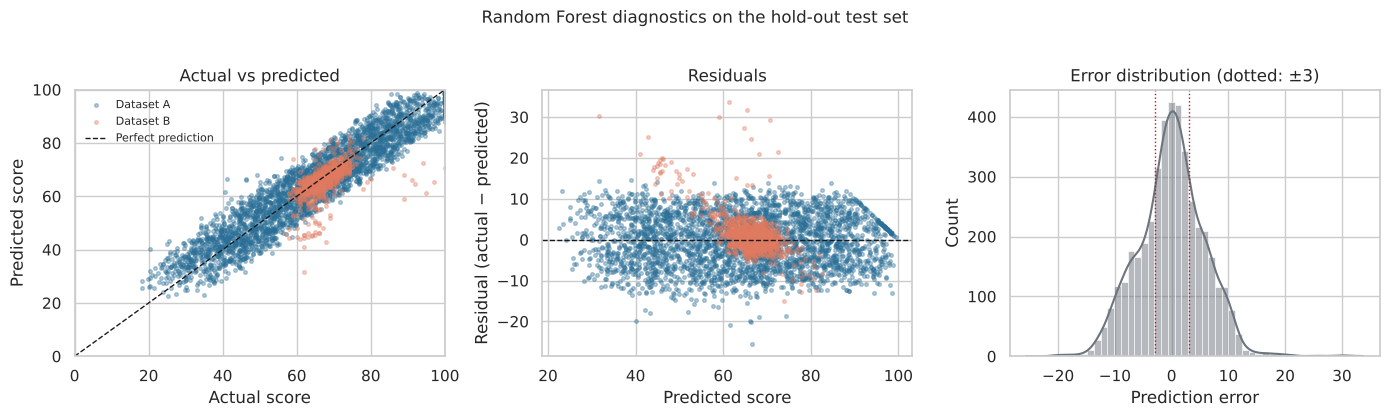

In [12]:
def diagnostics(name, fig_no, fname):
    p = preds[name]; r = y_test.values - p
    src = test_df.source.values
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for s in ["A", "B"]:
        m = src == s
        axes[0].scatter(y_test.values[m], p[m], s=7, alpha=0.35, color=PALETTE[s], label=f"Dataset {s}")
        axes[1].scatter(p[m], r[m], s=7, alpha=0.35, color=PALETTE[s])
    lo, hi = 0, 100
    axes[0].plot([lo, hi], [lo, hi], "k--", lw=1, label="Perfect prediction")
    axes[0].set(xlabel="Actual score", ylabel="Predicted score", title="Actual vs predicted", xlim=(lo, hi), ylim=(lo, hi))
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].axhline(0, color="k", ls="--", lw=1)
    axes[1].set(xlabel="Predicted score", ylabel="Residual (actual − predicted)", title="Residuals")
    sns.histplot(r, bins=50, kde=True, color="#6c757d", ax=axes[2])
    for b in (-3, 3): axes[2].axvline(b, color="#c1121f", ls=":", lw=1)
    axes[2].set(xlabel="Prediction error", title="Error distribution (dotted: ±3)")
    fig.suptitle(f"{name} diagnostics on the hold-out test set", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR + fname, bbox_inches="tight"); plt.show()

diagnostics("Random Forest", "4.3", "fig4_3_rf_diagnostics.png")

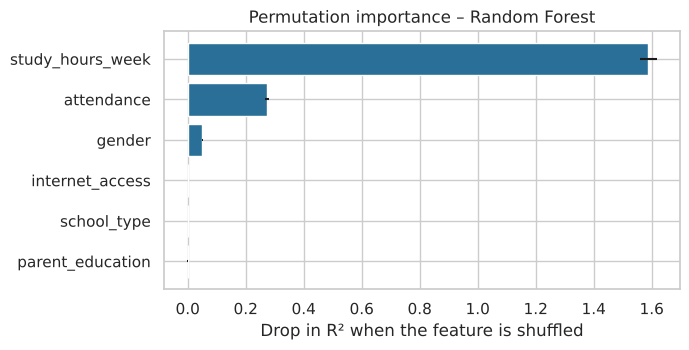

,mean,sd,share %
feature,,,
study_hours_week,1.5883,0.0283,83.1201
attendance,0.2721,0.0065,14.2407
gender,0.0501,0.0017,2.6232
internet_access,0.0003,0.0006,0.0160
school_type,-0.0000,0.0006,0.0000
parent_education,-0.0001,0.0008,0.0000


In [13]:
def perm_importance(name, fig_no, fname, color):
    pi = permutation_importance(fitted[name], X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                                scoring="r2", n_jobs=1)
    imp = pd.DataFrame({"feature": FEATURES, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean")
    imp["share %"] = 100 * imp["mean"].clip(lower=0) / imp["mean"].clip(lower=0).sum()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.barh(imp.feature, imp["mean"], xerr=imp["sd"], color=color)
    ax.set(xlabel="Drop in R² when the feature is shuffled", title=f"Permutation importance – {name}")
    fig.tight_layout(); fig.savefig(FIG_DIR + fname, bbox_inches="tight"); plt.show()
    return imp.sort_values("mean", ascending=False).set_index("feature").round(4)

imp_rf = perm_importance("Random Forest", "4.4", "fig4_4_rf_importance.png", PALETTE["A"])
imp_rf

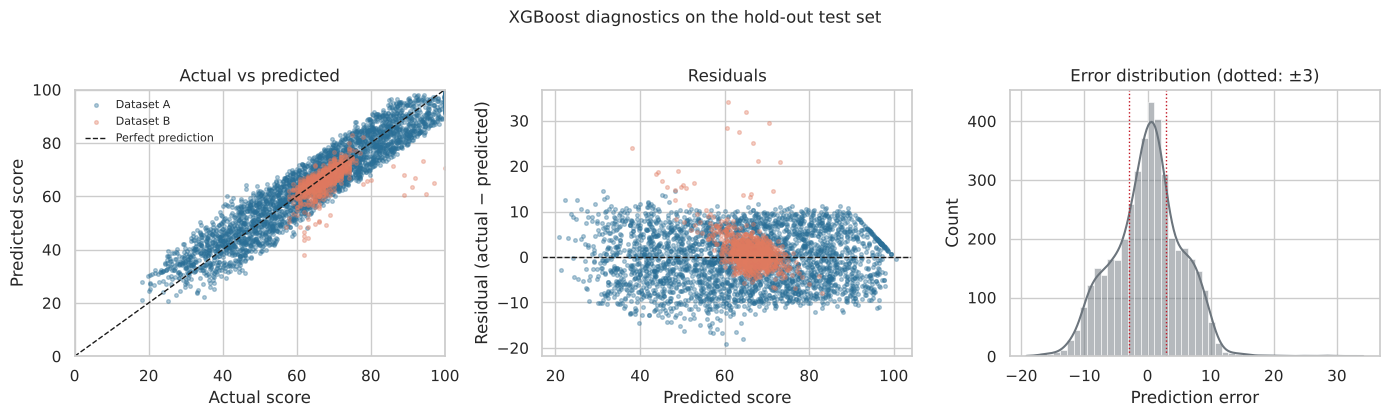

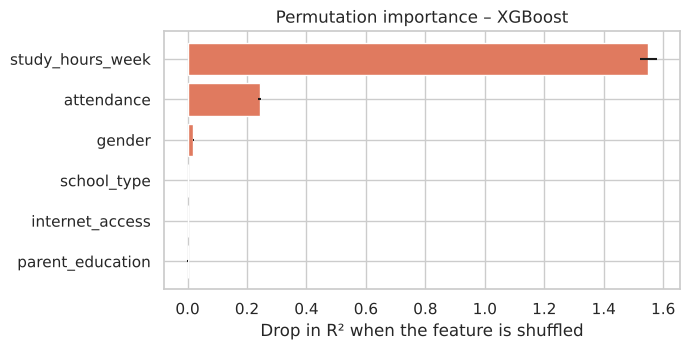

,mean,sd,share %
feature,,,
study_hours_week,1.5505,0.0272,85.4914
attendance,0.2427,0.0055,13.3840
gender,0.0197,0.0014,1.0882
school_type,0.0004,0.0003,0.0212
internet_access,0.0003,0.0003,0.0152
parent_education,0.0000,0.0004,0.0001


In [14]:
diagnostics("XGBoost", "4.5", "fig4_5_xgb_diagnostics.png")
imp_xgb = perm_importance("XGBoost", "4.6", "fig4_6_xgb_importance.png", PALETTE["B"])
imp_xgb

Stacking meta-learner (Ridge) weights: RF = 0.029, XGBoost = 0.970, intercept = 0.035
Correlation between RF and XGBoost hold-out predictions: r = 0.990


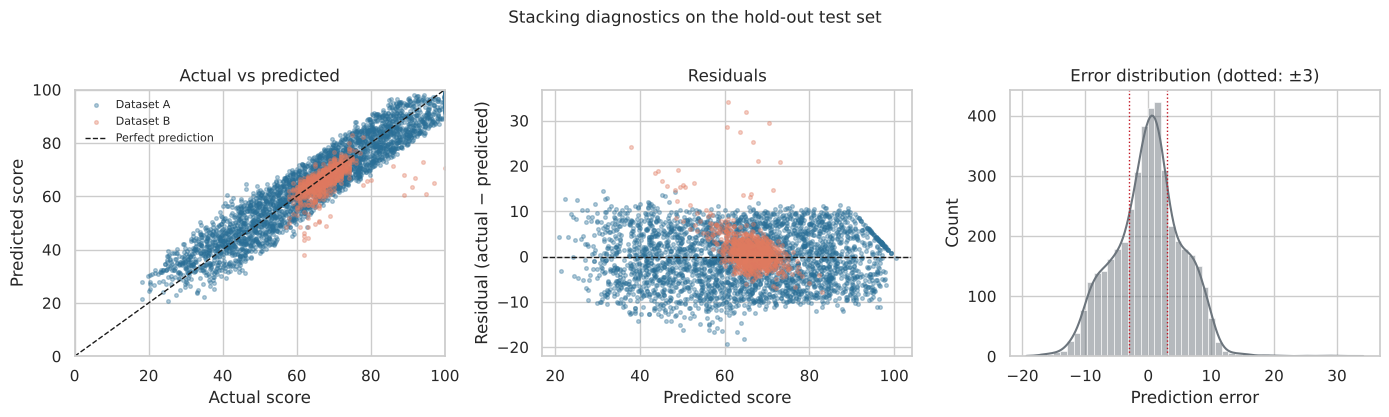

In [15]:
diagnostics("Stacking", "4.7", "fig4_7_stack_diagnostics.png")
meta = fitted["Stacking"].named_steps["model"].final_estimator_
print("Stacking meta-learner (Ridge) weights: RF = %.3f, XGBoost = %.3f, intercept = %.3f"
      % (meta.coef_[0], meta.coef_[1], meta.intercept_))
print("Correlation between RF and XGBoost hold-out predictions: r = %.3f" % np.corrcoef(preds["Random Forest"], preds["XGBoost"])[0, 1])

## 9. Learning curves

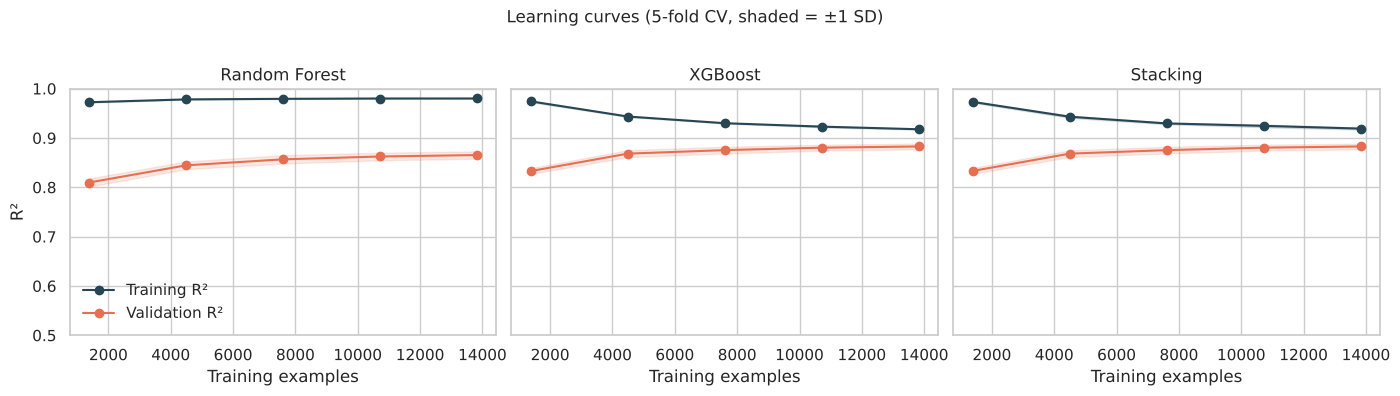

,train R2 (full),val R2 (full),gap
Model,,,
Random Forest,0.9801,0.8654,0.1147
XGBoost,0.9177,0.8828,0.0349
Stacking,0.9190,0.8828,0.0362


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
lc_rows = []
for ax, name in zip(axes, ["Random Forest", "XGBoost", "Stacking"]):
    sizes, tr, va = learning_curve(build_models()[name], X_train, y_train, cv=cv, scoring="r2",
                                   train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1)
    ax.plot(sizes, tr.mean(1), "o-", label="Training R²", color="#264653")
    ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=0.15, color="#264653")
    ax.plot(sizes, va.mean(1), "o-", label="Validation R²", color="#e76f51")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15, color="#e76f51")
    ax.set(title=name, xlabel="Training examples"); ax.set_ylim(0.5, 1.0)
    lc_rows.append({"Model": name, "train R2 (full)": tr.mean(1)[-1], "val R2 (full)": va.mean(1)[-1],
                    "gap": tr.mean(1)[-1] - va.mean(1)[-1]})
axes[0].set_ylabel("R²"); axes[0].legend(frameon=False)
fig.suptitle("Learning curves (5-fold CV, shaded = ±1 SD)", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_8_learning_curves.png", bbox_inches="tight"); plt.show()
lc_table = pd.DataFrame(lc_rows).set_index("Model").round(4)
lc_table

## 10. Model comparison (cross-validated)

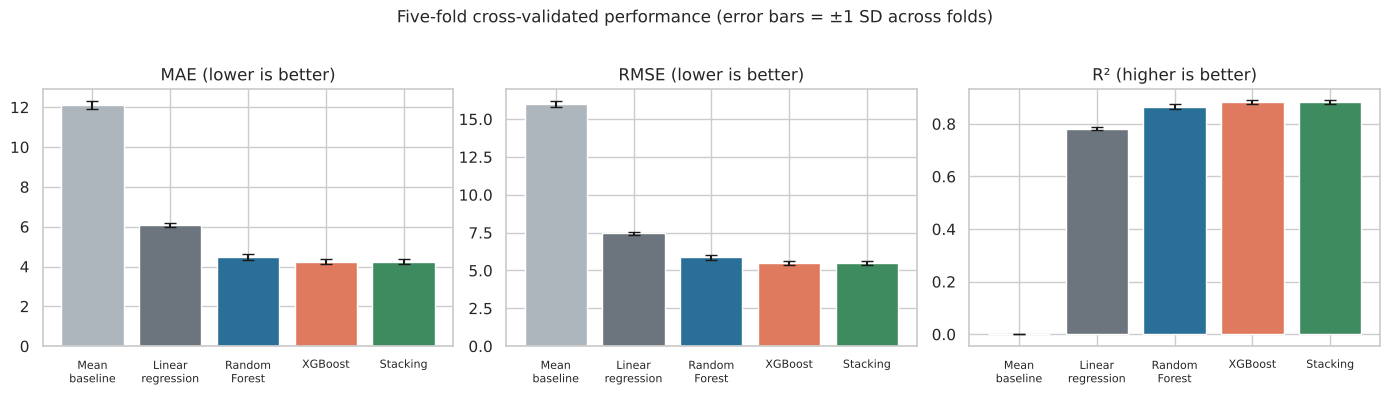

In [17]:
order = ["Mean baseline", "Linear regression", "Random Forest", "XGBoost", "Stacking"]
colors = ["#adb5bd", "#6c757d", PALETTE["A"], PALETTE["B"], PALETTE["C"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, m in zip(axes, ["MAE", "RMSE", "R2"]):
    ax.bar(range(len(order)), cv_table.loc[order, f"{m} mean"], yerr=cv_table.loc[order, f"{m} sd"],
           color=colors, capsize=4)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace(" ", "\n") for o in order], fontsize=8)
    ax.set_title(m.replace("R2", "R²") + (" (higher is better)" if m == "R2" else " (lower is better)"))
fig.suptitle("Five-fold cross-validated performance (error bars = ±1 SD across folds)", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_9_model_comparison.png", bbox_inches="tight"); plt.show()

## 11. Does combining the two sources help?

Each model family is trained on A only, B only, and A+B (pooled), then scored on the A and B portions of the same hold-out test set.

In [18]:
ms_rows = []
for train_name, tr in [("A only", train_df[train_df.source == "A"]),
                       ("B only", train_df[train_df.source == "B"]),
                       ("A + B (pooled)", train_df)]:
    for mname in ["Linear regression", "Random Forest", "Stacking"]:
        model = build_models()[mname].fit(tr[FEATURES], tr["score"])
        for s in ["A", "B"]:
            te = test_df[test_df.source == s]
            p = model.predict(te[FEATURES])
            ms_rows.append({"Training data": train_name, "Model": mname, "Test on": s, **metrics(te["score"], p)})
ms_table = pd.DataFrame(ms_rows)
ms_pivot = ms_table.pivot_table(index=["Model", "Training data"], columns="Test on", values=["MAE", "R2"]).round(3)
ms_pivot

MAE             R2        
Test on                                A       B      A       B
Model             Training data                                
Linear regression A + B (pooled)   5.805   6.745  0.864  -3.285
                  A only           4.941  12.555  0.910 -11.049
                  B only          12.625   1.536  0.364   0.529
Random Forest     A + B (pooled)   5.385   2.505  0.889  -0.193
                  A only           5.257  12.418  0.896 -11.236
                  B only          13.611   1.887  0.267   0.368
Stacking          A + B (pooled)   5.180   2.182  0.898   0.134
                  A only           5.113  12.844  0.903 -11.668
                  B only          13.761   1.706  0.244   0.460

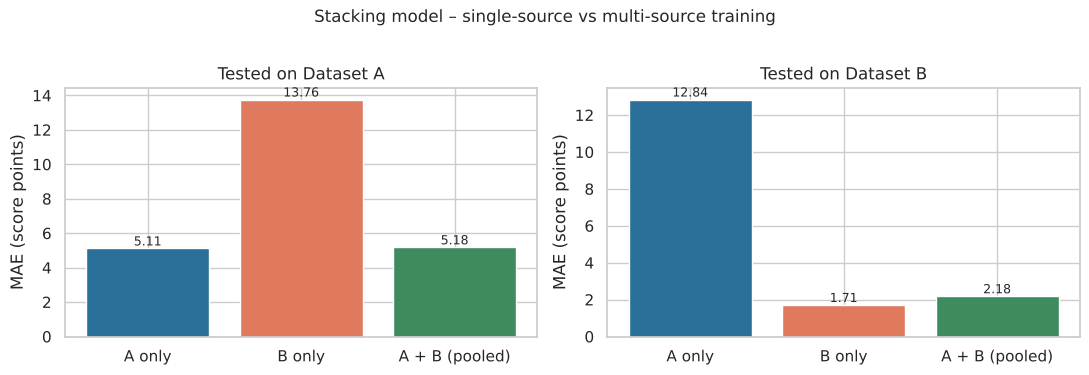

In [19]:
sub = ms_table[ms_table.Model == "Stacking"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, s in zip(axes, ["A", "B"]):
    d = sub[sub["Test on"] == s].set_index("Training data").loc[["A only", "B only", "A + B (pooled)"]]
    bars = ax.bar(d.index, d["MAE"], color=["#2a6f97", "#e07a5f", "#3d8b5f"])
    for b, v in zip(bars, d["MAE"]): ax.text(b.get_x() + b.get_width()/2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set(title=f"Tested on Dataset {s}", ylabel="MAE (score points)")
fig.suptitle("Stacking model – single-source vs multi-source training", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_10_multisource.png", bbox_inches="tight"); plt.show()

## 12. External validation on Dataset C (Nabeel, synthetic, 1,000,000 students)

Dataset C shares only two predictors with the development data: weekly study hours and attendance. The models are therefore re-trained on the **full development set (A+B) using only those two features** and then applied, unchanged, to all of Dataset C. The internal reference uses the same two features on the same hold-out split. Spearman's ρ is added because it measures whether the model *ranks* students correctly even if the score level differs.

In [20]:
NUM2 = ["study_hours_week", "attendance"]
ext_rows, ext_preds = [], {}
for name in ["Mean baseline", "Linear regression", "Random Forest", "XGBoost", "Stacking"]:
    # internal reference (2 features, same split)
    m_int = build_models(NUM2, [])[name].fit(train_df[NUM2], y_train)
    p_int = m_int.predict(test_df[NUM2])
    # final model on all development data, then external
    m_ext = build_models(NUM2, [])[name].fit(dev[NUM2], dev["score"])
    p_ext = m_ext.predict(C[NUM2]); ext_preds[name] = p_ext
    rho = spearmanr(C["score"], p_ext).correlation if name != "Mean baseline" else np.nan
    ext_rows.append({"Model": name,
                     **{f"Internal {k}": v for k, v in metrics(y_test, p_int).items()},
                     **{f"External {k}": v for k, v in metrics(C["score"], p_ext).items()},
                     "External Spearman rho": rho,
                     "External mean error (actual − predicted)": float(np.mean(C["score"] - p_ext))})
ext_table = pd.DataFrame(ext_rows).set_index("Model")
ext_table.round(4)

,Internal MAE,Internal RMSE,Internal R2,External MAE,External RMSE,External R2,External Spearman rho,External mean error (actual − predicted)
Model,,,,,,,,
Mean baseline,12.2001,16.1607,-0.0000,21.7806,24.6990,-1.5613,NaN,19.2837
Linear regression,6.3996,7.7803,0.7682,27.3674,29.4729,-2.6471,0.7213,27.1500
Random Forest,4.5646,6.0369,0.8605,29.0222,31.6369,-3.2023,0.3395,27.2901
XGBoost,4.2597,5.4510,0.8862,28.9077,31.2682,-3.1050,0.3827,27.1265
Stacking,4.2581,5.4499,0.8863,28.7088,31.0456,-3.0467,0.3899,26.9346


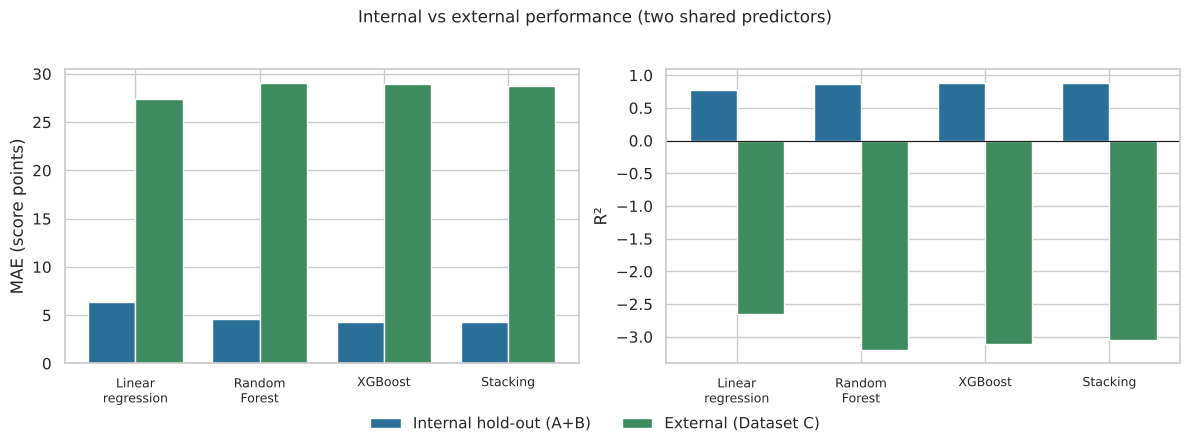

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = ["Linear regression", "Random Forest", "XGBoost", "Stacking"]
x = np.arange(len(names)); w = 0.38
for ax, m, lab in [(axes[0], "MAE", "MAE (score points)"), (axes[1], "R2", "R²")]:
    ax.bar(x - w/2, ext_table.loc[names, f"Internal {m}"], w, label="Internal hold-out (A+B)", color=PALETTE["A"])
    ax.bar(x + w/2, ext_table.loc[names, f"External {m}"], w, label="External (Dataset C)", color=PALETTE["C"])
    ax.set_xticks(x); ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9); ax.set_ylabel(lab)
    ax.axhline(0, color="k", lw=0.8)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Internal vs external performance (two shared predictors)", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR + "fig4_11_internal_external.png", bbox_inches="tight"); plt.show()

In [22]:
# Where does the external error come from? Compare predicted vs actual mean, and the slope of score on study hours.
p = ext_preds["Stacking"]
print(f"Dataset C actual mean score   : {C.score.mean():.2f}")
print(f"Stacking mean predicted score : {p.mean():.2f}")
slope = lambda d: np.polyfit(d.study_hours_week, d.score, 1)[0]
print(f"Score gain per extra weekly study hour  -> A: {slope(A):.2f} | B: {slope(B):.2f} | C: {slope(C):.2f}")
print(f"Pearson r (actual vs predicted) on C: {pearsonr(C.score, p)[0]:.3f}")

Dataset C actual mean score   : 84.28
Stacking mean predicted score : 57.35
Score gain per extra weekly study hour  -> A: 1.13 | B: 0.29 | C: 1.82
Pearson r (actual vs predicted) on C: 0.300


### 12.1 How much of the external error is a level shift? (linear recalibration)

A simple recalibration is fitted on a random 1 % of Dataset C (about 10,000 students): `score_C ≈ a + b × prediction`. It is then evaluated on the remaining 99 %. This is *not* part of the external test above; it shows how much of the failure comes from the different score scale of Dataset C rather than from the ranking of students.

In [23]:
rng = np.random.RandomState(RANDOM_STATE)
cal_idx = rng.rand(len(C)) < 0.01
recal_rows = []
for name in ["Linear regression", "Random Forest", "XGBoost", "Stacking"]:
    p = ext_preds[name]
    lr = LinearRegression().fit(p[cal_idx].reshape(-1, 1), C.score.values[cal_idx])
    p_cal = lr.predict(p[~cal_idx].reshape(-1, 1))
    recal_rows.append({"Model": name, "calibration n": int(cal_idx.sum()), "a": lr.intercept_, "b": lr.coef_[0],
                       **{f"Recalibrated {k}": v for k, v in metrics(C.score.values[~cal_idx], p_cal).items()}})
recal_table = pd.DataFrame(recal_rows).set_index("Model")
recal_table.round(4)

,calibration n,a,b,Recalibrated MAE,Recalibrated RMSE,Recalibrated R2
Model,,,,,,
Linear regression,9979,2.7974,1.4277,8.7421,11.0126,0.4908
Random Forest,9979,60.4187,0.4211,11.9516,14.8386,0.0756
XGBoost,9979,57.2805,0.4748,11.7643,14.7490,0.0867
Stacking,9979,56.0302,0.4951,11.7209,14.7240,0.0898


## 13. Summary of key numbers (used in the thesis)

In [24]:
best = cv_table["MAE mean"].idxmin()
print("Development set size after de-duplication:", f"{len(dev):,}")
print("Best model by CV MAE:", best)
print(cv_table.loc[["Mean baseline", "Linear regression", "Random Forest", "XGBoost", "Stacking"],
                   ["MAE mean", "MAE sd", "RMSE mean", "RMSE sd", "R2 mean", "R2 sd"]].round(3).to_string())
print()
print(holdout_table[["MAE", "RMSE", "R2", "R2 within A", "R2 within B", "MAE within A", "MAE within B"]].round(3).to_string())
print()
print(ext_table.round(3).to_string())

Development set size after de-duplication: 21,607
Best model by CV MAE: XGBoost
                   MAE mean  MAE sd  RMSE mean  RMSE sd  R2 mean  R2 sd
Model                                                                  
Mean baseline        12.117   0.200     15.992    0.213   -0.000  0.000
Linear regression     6.093   0.087      7.462    0.099    0.782  0.007
Random Forest         4.474   0.142      5.865    0.177    0.865  0.008
XGBoost               4.239   0.129      5.471    0.140    0.883  0.007
Stacking              4.240   0.130      5.472    0.141    0.883  0.006

                      MAE    RMSE     R2  R2 within A  R2 within B  MAE within A  MAE within B
Model                                                                                         
Mean baseline      12.200  16.161 -0.000       -0.003       -0.313        16.107         3.334
Linear regression   6.092   7.452  0.787        0.864       -3.285         5.805         6.745
Random Forest       4.504   5.842  

## Appendix: how much did the earlier mistakes inflate the results?

The earlier pipeline is reproduced here (duplicates kept, `source` used as a feature, daily/weekly hours mixed, B's parental involvement used as parent education) to quantify the difference.

In [25]:
old_A = lower_strings(df_A_raw)[["study_hours", "attendance_percentage", "parent_education", "school_type", "internet_access", "gender", "overall_score"]].assign(source="A")
old_B = lower_strings(df_B_raw).rename(columns={"hours_studied": "study_hours"})
old_B = lower_strings(df_B_raw).rename(columns={"Hours_Studied": "study_hours", "Attendance": "attendance_percentage",
            "Parental_Involvement": "parent_education", "School_Type": "school_type", "Internet_Access": "internet_access",
            "Gender": "gender", "Exam_Score": "overall_score"})[old_A.columns[:-1]].assign(source="B")
old = pd.concat([old_A, old_B], ignore_index=True)
Xo, yo = old.drop(columns="overall_score"), old["overall_score"]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, yo, test_size=0.2, random_state=42)
old_prep = make_preprocessor(["study_hours", "attendance_percentage"], ["parent_education", "school_type", "internet_access", "gender", "source"])
old_rf = Pipeline([("prep", old_prep), ("model", rf())]).fit(Xo_tr, yo_tr)
print("Earlier pipeline, Random Forest:", {k: round(v, 4) for k, v in metrics(yo_te, old_rf.predict(Xo_te)).items()})
key = lambda d: d.astype(str).agg("|".join, axis=1)
leak = key(Xo_te.assign(y=yo_te)).isin(set(key(Xo_tr.assign(y=yo_tr)))).mean()
print(f"Share of earlier test rows that also appeared verbatim in the training set: {100*leak:.1f}%")

Earlier pipeline, Random Forest: {'MAE': 3.0419, 'RMSE': np.float64(4.3904), 'R2': 0.9338}
Share of earlier test rows that also appeared verbatim in the training set: 42.3%


## 14. Real-data test: UCI Student Performance (Cortez & Silva, 2008)

Dataset D is real: final-year records from two Portuguese secondary schools for a Mathematics course (395 students) and a Portuguese-language course (649 students), CC BY 4.0, DOI 10.24432/C5TG7T. The two courses are analysed separately, because 382 students appear in both files.

**Harmonisation to the development schema**

| Development variable | UCI source | Mapping |
|---|---|---|
| `study_hours_week` | `studytime` (1: <2 h, 2: 2–5 h, 3: 5–10 h, 4: >10 h per week) | interval mid-points 1, 3.5, 7.5, 12 h (assumption for the open top band) |
| `parent_education` | max(`Medu`, `Fedu`) (0 none … 3 secondary, 4 higher) | 0–3 → secondary_or_less; 4 → tertiary (UCI does not separate postgraduate) |
| `internet_access` | `internet` | yes / no |
| `gender` | `sex` | F → female, M → male |
| `score` | `G3` (0–20) | × 5 → 0–100 |

Attendance is not available as a percentage in UCI (only an absence count), and school type is not recorded, so the transfer models use the **four** shared predictors. G1 and G2 are never used, because they are earlier grades in the same course and would leak the outcome.

In [26]:
def load_uci(path, course):
    d = pd.read_csv(path, sep=";")
    out = pd.DataFrame({
        "study_hours_week": d["studytime"].map({1: 1.0, 2: 3.5, 3: 7.5, 4: 12.0}),
        "parent_education": np.where(np.maximum(d["Medu"], d["Fedu"]) >= 4, "tertiary", "secondary_or_less"),
        "internet_access": d["internet"].str.lower(),
        "gender": d["sex"].map({"F": "female", "M": "male"}),
        "score": d["G3"] * 5.0,
    })
    out["course"] = course
    return out, d

D_mat, uci_mat_raw = load_uci(DATA_DIR + "student-mat.csv", "Mathematics")
D_por, uci_por_raw = load_uci(DATA_DIR + "student-por.csv", "Portuguese")
for name, d in [("Mathematics", D_mat), ("Portuguese", D_por)]:
    print(f"{name}: {len(d)} students | score mean {d.score.mean():.1f} (SD {d.score.std():.1f}) | "
          f"G3 = 0: {(d.score == 0).sum()} | r(study hours, score) = {d[['study_hours_week','score']].corr().iloc[0,1]:.3f}")

Mathematics: 395 students | score mean 52.1 (SD 22.9) | G3 = 0: 38 | r(study hours, score) = 0.101
Portuguese: 649 students | score mean 59.5 (SD 16.2) | G3 = 0: 15 | r(study hours, score) = 0.235


In [27]:
FEAT4_NUM, FEAT4_CAT = ["study_hours_week"], ["parent_education", "internet_access", "gender"]
FEAT4 = FEAT4_NUM + FEAT4_CAT

# development data restricted to the 4 shared predictors; A's parent education collapsed to the 2 UCI levels
dev4 = dev.copy()
dev4["parent_education"] = dev4["parent_education"].replace({"postgraduate": "tertiary"})

uci_rows, uci_preds = [], {}
for name in ["Mean baseline", "Linear regression", "Random Forest", "XGBoost", "Stacking"]:
    model = build_models(FEAT4_NUM, FEAT4_CAT)[name].fit(dev4[FEAT4], dev4["score"])
    for course, D in [("Mathematics", D_mat), ("Portuguese", D_por)]:
        p = model.predict(D[FEAT4]); uci_preds[(name, course)] = p
        row = {"Model": name, "Course": course, **metrics(D["score"], p),
               "Spearman rho": (spearmanr(D["score"], p).correlation if name != "Mean baseline" else np.nan),
               "mean error (actual − predicted)": float(np.mean(D["score"] - p))}
        uci_rows.append(row)
uci_transfer = pd.DataFrame(uci_rows).set_index(["Course", "Model"])
uci_transfer.round(3)

,,MAE,RMSE,R2,Spearman rho,mean error (actual − predicted)
Course,Model,,,,,
Mathematics,Mean baseline,19.557,26.276,-0.319,NaN,-12.924
Portuguese,Mean baseline,12.743,17.043,-0.115,NaN,-5.470
Mathematics,Linear regression,19.021,23.929,-0.094,0.083,7.319
Portuguese,Linear regression,18.183,21.898,-0.841,0.205,15.167
Mathematics,Random Forest,23.180,28.329,-0.533,0.082,5.070
Portuguese,Random Forest,23.210,27.053,-1.809,-0.083,11.217
Mathematics,XGBoost,21.754,26.907,-0.383,0.118,5.316
Portuguese,XGBoost,21.182,25.312,-1.459,-0.044,12.056
Mathematics,Stacking,21.307,26.483,-0.340,0.117,5.182


### 14.1 Reference: models trained on the real data itself (five-fold CV within each course)

This shows how predictable the real outcome is from (i) the same four shared predictors and (ii) all 30 UCI predictors (excluding G1 and G2). It is the ceiling against which the transferred models should be judged.

In [28]:
def uci_full_features(raw):
    X = raw.drop(columns=["G1", "G2", "G3"]).copy()
    return X, raw["G3"] * 5.0

local_rows = []
cv10 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for course, D, raw in [("Mathematics", D_mat, uci_mat_raw), ("Portuguese", D_por, uci_por_raw)]:
    Xf, yf = uci_full_features(raw)
    num_f = Xf.select_dtypes(exclude="object").columns.tolist()
    cat_f = [c for c in Xf.columns if c not in num_f]
    for fs_name, X, y, num, cat in [("4 shared predictors", D[FEAT4], D["score"], FEAT4_NUM, FEAT4_CAT),
                                     ("all 30 predictors", Xf, yf, num_f, cat_f)]:
        for name in ["Mean baseline", "Linear regression", "Random Forest", "XGBoost", "Stacking"]:
            res = cross_validate(build_models(num, cat)[name], X, y, cv=cv10, scoring=scoring, n_jobs=1)
            local_rows.append({"Course": course, "Features": fs_name, "Model": name,
                               "MAE mean": -res["test_MAE"].mean(), "MAE sd": res["test_MAE"].std(ddof=1),
                               "RMSE mean": -res["test_RMSE"].mean(), "R2 mean": res["test_R2"].mean(), "R2 sd": res["test_R2"].std(ddof=1)})
uci_local = pd.DataFrame(local_rows).set_index(["Course", "Features", "Model"])
uci_local.round(3)

MAE mean  ...  R2 sd
Course      Features            Model                        ...       
Mathematics 4 shared predictors Mean baseline        17.170  ...  0.010
                                Linear regression    16.978  ...  0.060
                                Random Forest        18.026  ...  0.090
                                XGBoost              18.072  ...  0.094
                                Stacking             17.283  ...  0.028
            all 30 predictors   Mean baseline        17.170  ...  0.010
                                Linear regression    17.093  ...  0.169
                                Random Forest        14.271  ...  0.040
                                XGBoost              15.174  ...  0.107
                                Stacking             14.847  ...  0.067
Portuguese  4 shared predictors Mean baseline        12.052  ...  0.014
                                Linear regression    11.110  ...  0.081
                                Random Forest        11.176  ...  0.145
                                XGBoost              11.209  ...  0.169
                                Stacking             11.220  ...  0.067
            all 30 predictors   Mean baseline        12.052  ...  0.014
                                Linear regression    10.023  ...  0.096
                                Random Forest        10.077  ...  0.077
                                XGBoost              10.459  ...  0.081
                                Stacking             10.068  ...  0.076

[20 rows x 5 columns]

In [29]:
# Recalibration on 20% of each course (diagnostic), evaluated on the remaining 80%
rng = np.random.RandomState(RANDOM_STATE)
recal_uci = []
for course, D in [("Mathematics", D_mat), ("Portuguese", D_por)]:
    idx = rng.rand(len(D)) < 0.2
    for name in ["Linear regression", "XGBoost", "Stacking"]:
        p = uci_preds[(name, course)]
        lr = LinearRegression().fit(p[idx].reshape(-1, 1), D["score"].values[idx])
        pc = lr.predict(p[~idx].reshape(-1, 1))
        recal_uci.append({"Course": course, "Model": name, "n calibration": int(idx.sum()),
                          **{f"Recalibrated {k}": v for k, v in metrics(D["score"].values[~idx], pc).items()}})
recal_uci = pd.DataFrame(recal_uci).set_index(["Course", "Model"])
recal_uci.round(3)

n calibration  ...  Recalibrated R2
Course      Model                             ...                 
Mathematics Linear regression             90  ...           -0.078
            XGBoost                       90  ...           -0.013
            Stacking                      90  ...           -0.012
Portuguese  Linear regression            143  ...            0.018
            XGBoost                      143  ...            0.006
            Stacking                     143  ...            0.002

[6 rows x 4 columns]

In [30]:
# Sensitivity: excluding students with G3 = 0 (usually absent from the final exam)
sens = []
for course, D in [("Mathematics", D_mat), ("Portuguese", D_por)]:
    m = (D["score"] > 0).values
    for name in ["Linear regression", "Stacking"]:
        p = uci_preds[(name, course)]
        sens.append({"Course": course, "Model": name, "n": int(m.sum()), **metrics(D["score"].values[m], p[m]),
                     "Spearman rho": spearmanr(D["score"].values[m], p[m]).correlation})
sens_g3 = pd.DataFrame(sens).set_index(["Course", "Model"])
sens_g3.round(3)

n     MAE    RMSE     R2  Spearman rho
Course      Model                                                      
Mathematics Linear regression  357  16.293  20.505 -0.619         0.087
            Stacking           357  18.418  22.514 -0.952         0.164
Portuguese  Linear regression  634  17.604  21.163 -1.476         0.187
            Stacking           634  19.892  23.875 -2.152        -0.040

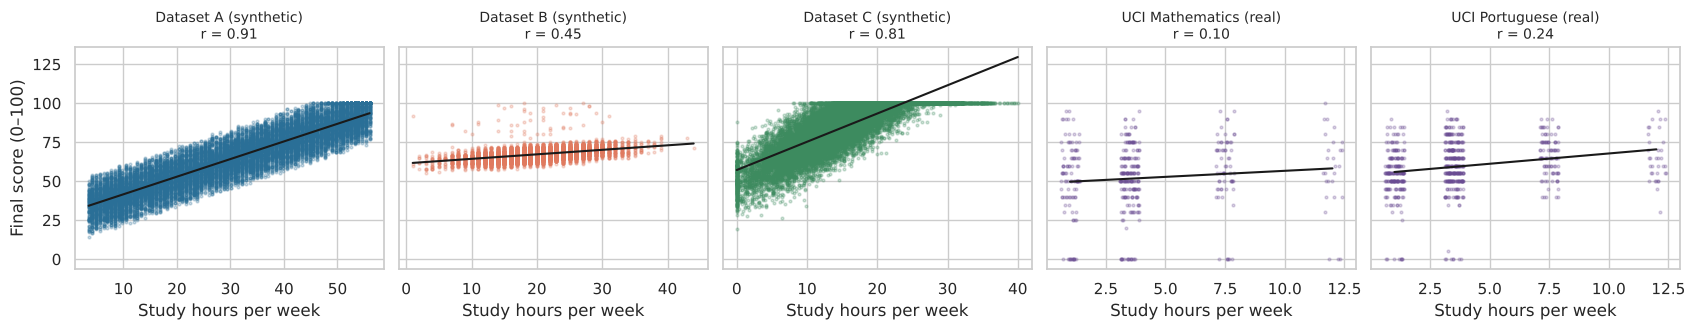

,r,slope (points per weekly hour)
Dataset A (synthetic),0.906,1.131
Dataset B (synthetic),0.446,0.289
Dataset C (synthetic),0.812,1.811
UCI Mathematics (real),0.101,0.777
UCI Portuguese (real),0.235,1.320


In [31]:
# Figure P2: score vs weekly study hours in every dataset (the core contrast)
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
panels = [("Dataset A (synthetic)", A, PALETTE["A"]), ("Dataset B (synthetic)", B, PALETTE["B"]),
          ("Dataset C (synthetic)", C.sample(20000, random_state=RANDOM_STATE), PALETTE["C"]),
          ("UCI Mathematics (real)", D_mat, "#6a4c93"), ("UCI Portuguese (real)", D_por, "#6a4c93")]
slope_tbl = {}
for ax, (title, d, col) in zip(axes, panels):
    jitter = np.random.RandomState(0).uniform(-0.4, 0.4, len(d)) if "UCI" in title else 0
    ax.scatter(d["study_hours_week"] + jitter, d["score"], s=4, alpha=0.25, color=col)
    b1, b0 = np.polyfit(d["study_hours_week"], d["score"], 1)
    xs = np.linspace(d["study_hours_week"].min(), d["study_hours_week"].max(), 50)
    ax.plot(xs, b0 + b1 * xs, color="k", lw=1.5)
    r = d[["study_hours_week", "score"]].corr().iloc[0, 1]
    slope_tbl[title] = {"r": r, "slope (points per weekly hour)": b1}
    ax.set_title(f"{title}\nr = {r:.2f}", fontsize=10); ax.set_xlabel("Study hours per week")
axes[0].set_ylabel("Final score (0–100)")
fig.tight_layout(); fig.savefig(FIG_DIR + "figP2_study_hours_vs_score.png", bbox_inches="tight"); plt.show()
pd.DataFrame(slope_tbl).T.round(3)

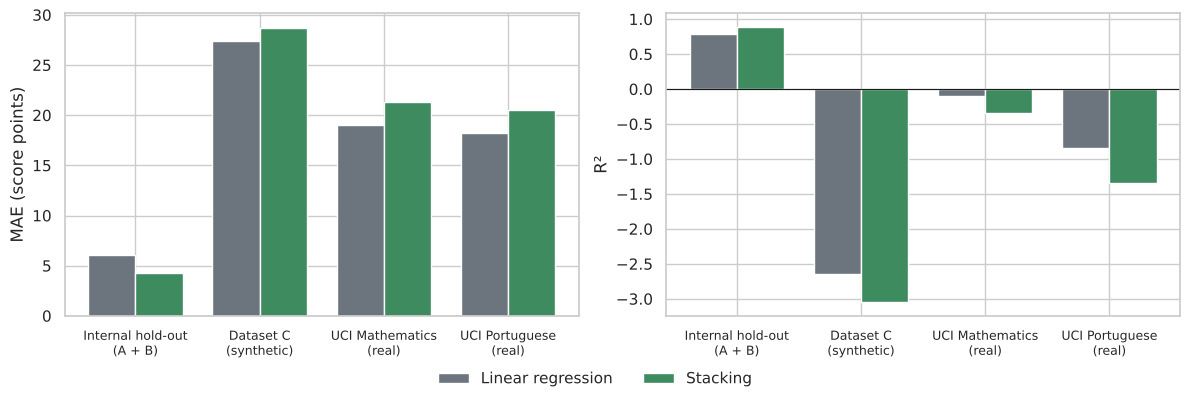

,Target,Model,MAE,R2
0,Internal hold-out\n(A + B),Linear regression,6.092,0.787
1,Dataset C\n(synthetic),Linear regression,27.367,-2.647
2,UCI Mathematics\n(real),Linear regression,19.021,-0.094
3,UCI Portuguese\n(real),Linear regression,18.183,-0.841
4,Internal hold-out\n(A + B),Stacking,4.263,0.885
5,Dataset C\n(synthetic),Stacking,28.709,-3.047
6,UCI Mathematics\n(real),Stacking,21.307,-0.340
7,UCI Portuguese\n(real),Stacking,20.530,-1.350


In [32]:
# Figure P5: transfer performance summary across targets (Stacking and linear regression)
rows = []
for nm in ["Linear regression", "Stacking"]:
    rows.append(("Internal hold-out\n(A + B)", nm, holdout_table.loc[nm, "MAE"], holdout_table.loc[nm, "R2"]))
    rows.append(("Dataset C\n(synthetic)", nm, ext_table.loc[nm, "External MAE"], ext_table.loc[nm, "External R2"]))
    for course in ["Mathematics", "Portuguese"]:
        rows.append((f"UCI {course}\n(real)", nm, uci_transfer.loc[(course, nm), "MAE"], uci_transfer.loc[(course, nm), "R2"]))
tp = pd.DataFrame(rows, columns=["Target", "Model", "MAE", "R2"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
targets = tp.Target.unique(); x = np.arange(len(targets)); w = 0.38
for ax, m in zip(axes, ["MAE", "R2"]):
    for k, (nm, col) in enumerate([("Linear regression", "#6c757d"), ("Stacking", PALETTE["C"])]):
        vals = tp[tp.Model == nm].set_index("Target").loc[targets, m]
        ax.bar(x + (k - 0.5) * w, vals, w, label=nm, color=col)
    ax.set_xticks(x); ax.set_xticklabels(targets, fontsize=9); ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("MAE (score points)" if m == "MAE" else "R²")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); fig.savefig(FIG_DIR + "figP5_transfer_summary.png", bbox_inches="tight"); plt.show()
tp.round(3)